# E03 — Multiresolution Bollinger Walk Dependence

Four independent native 20-bar indicators (4H, 1H, 15m, 5m), aligned only after their respective candle CLOSE. E03 is descriptive; walk episodes are not assumed independent. November is a visual test window; tables cover the full configured interval.

## 0. Setup
Keep `walk_states.py` from E02 and place `e03_analysis.py` beside this notebook. Paste the **verified** loading code for your 5-minute `bars` dataframe in the next cell, or run it before this notebook. It must have UTC-aligned 5m OPEN timestamps and open/high/low/close/volume.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from walk_states import bollinger_from_5m, detect_walk_states
from e03_analysis import (align_to_5m, occupancy, next_walk_probabilities,
                          cross_overlap, conditional_lift, plot_pair)

import requests
from pathlib import Path
import json

START, END = "2025-01-01", "2026-01-01"
TIMEFRAMES = {"4H":"4h", "1H":"1h", "15m":"15min", "5m":"5min"}
PARAMS = dict(near=0.15, confirm_bars=3, exit_bars=2, slope_bars=3)

NOV_START = "2025-11-13"
NOV_END = "2025-11-23"

CONFIGS = {"1D":"1D", "1H":"1h", "15m":"15min", "5m":"5min"}
WINDOW = 20
NEAR = 0.15
CONFIRM_BARS = 3
EXIT_BARS = 2
SLOPE_BARS = 3

REPO = Path("/media/ata/Data/personal/binbot")
DATA_DIR = REPO / "research" / "sentiment_price" / "data"
CACHE_DIR = DATA_DIR / "btcusdt_5m_batches"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# Warm-up before 2025 and a buffer for forward-return labels.
START = pd.Timestamp("2024-12-30", tz="UTC")
END = pd.Timestamp("2026-01-02", tz="UTC")  # exclusive

STEP_MS = 5 * 60 * 1000
START_MS = int(START.timestamp() * 1000)
END_MS = int(END.timestamp() * 1000)

print("Expected candles:", (END_MS - START_MS) // STEP_MS)

Expected candles: 105984


In [3]:
# TODO: paste verified 5-minute data loading code from 02_price_features.ipynb
all_candles = []
cursor = START_MS

with requests.Session() as session:
    while cursor < END_MS:
        batch_end = min(cursor + 1000 * STEP_MS, END_MS)
        cache_file = CACHE_DIR / f"{cursor}_{batch_end}.json"

        if cache_file.exists():
            batch = json.loads(cache_file.read_text())
        else:
            response = session.get(
                "https://api.binance.com/api/v3/klines",
                params={
                    "symbol": "BTCUSDT",
                    "interval": "5m",
                    "timeZone": "0",
                    "startTime": cursor,
                    "endTime": batch_end - 1,
                    "limit": 1000,
                },
                timeout=30,
            )
            response.raise_for_status()
            batch = response.json()

        if not isinstance(batch, list) or not batch:
            raise ValueError(f"Unexpected response at {cursor}: {batch}")

        # Require every expected candle; do not silently fill gaps.
        expected_opens = list(range(cursor, batch_end, STEP_MS))
        actual_opens = [int(row[0]) for row in batch]

        if actual_opens != expected_opens:
            raise ValueError(
                f"Missing, duplicate or unexpected candles in batch {cursor}"
            )

        if not cache_file.exists():
            temporary = cache_file.with_suffix(".tmp")
            temporary.write_text(json.dumps(batch))
            temporary.replace(cache_file)
            time.sleep(0.2)

        all_candles.extend(batch)
        cursor = batch_end

        print(
            f"\rLoaded {len(all_candles):,} candles",
            end="",
            flush=True,
        )

print("\nDownload/cache loading complete.")
columns = [
    "open_time", "open", "high", "low", "close", "volume",
    "close_time", "quote_volume", "trade_count",
    "taker_buy_volume", "taker_buy_quote_volume", "ignore",
]

bars = pd.DataFrame(all_candles, columns=columns)

bars["open_time"] = pd.to_datetime(bars["open_time"], unit="ms", utc=True)
bars["close_time"] = pd.to_datetime(bars["close_time"], unit="ms", utc=True)

numeric = [
    "open", "high", "low", "close", "volume", "quote_volume",
    "trade_count", "taker_buy_volume", "taker_buy_quote_volume",
]
bars[numeric] = bars[numeric].apply(pd.to_numeric, errors="raise")
bars = bars.set_index("open_time").sort_index()

expected_index = pd.date_range(
    START, END - pd.Timedelta(minutes=5), freq="5min"
)

assert bars.index.is_unique
assert bars.index.equals(expected_index), "Unexpected candle coverage"
assert bars[numeric].notna().all().all()
assert (bars[["open", "high", "low", "close"]] > 0).all().all()
assert (bars["low"] <= bars[["open", "close"]].min(axis=1)).all()
assert (bars["high"] >= bars[["open", "close"]].max(axis=1)).all()
assert (bars["volume"] >= 0).all()
assert "bars" in globals(), "Load your existing 5m OHLCV dataframe as bars first"

Loaded 105,984 candles
Download/cache loading complete.


## 1. Build independent native-timeframe walks

In [4]:
runs = {}
for label,resolution in TIMEFRAMES.items():
    bb = bollinger_from_5m(bars, START, END, resolution=resolution, window=20, num_std=2.0)
    states, transitions = detect_walk_states(bb, **PARAMS)
    runs[label] = {"bb":bb, "states":states, "transitions":transitions}
    print(label, "candles",len(bb), "transitions",len(transitions))

4H candles 2208 transitions 150
1H candles 8832 transitions 655
15m candles 35328 transitions 2525
5m candles 105984 transitions 8139


## 2. Causal 5-minute timeline
The latest **completed** higher-timeframe candle is carried forward; a state from an unfinished candle is never visible. Missing scheduled state rows remain unknown, not silently bridged.

In [5]:
aligned = align_to_5m(runs, TIMEFRAMES)
display(aligned.loc["2025-11-22":"2025-11-23"].head(12))
display(occupancy(aligned))

,4H,1H,15m,5m
close_time_utc,,,,
2025-11-22 00:00:00+00:00,NEUTRAL,NEUTRAL,NEUTRAL,NEUTRAL
2025-11-22 00:05:00+00:00,NEUTRAL,NEUTRAL,NEUTRAL,NEUTRAL
2025-11-22 00:10:00+00:00,NEUTRAL,NEUTRAL,NEUTRAL,NEUTRAL
2025-11-22 00:15:00+00:00,NEUTRAL,NEUTRAL,NEUTRAL,UPPER_WALK
2025-11-22 00:20:00+00:00,NEUTRAL,NEUTRAL,NEUTRAL,UPPER_WALK
2025-11-22 00:25:00+00:00,NEUTRAL,NEUTRAL,NEUTRAL,NEUTRAL
2025-11-22 00:30:00+00:00,NEUTRAL,NEUTRAL,NEUTRAL,NEUTRAL
2025-11-22 00:35:00+00:00,NEUTRAL,NEUTRAL,NEUTRAL,NEUTRAL
2025-11-22 00:40:00+00:00,NEUTRAL,NEUTRAL,NEUTRAL,NEUTRAL


count_5m  fraction
timeframe state                         
4H        LOWER_WALK      8880  0.083823
          UPPER_WALK      8784  0.082917
          NEUTRAL        88273  0.833259
1H        LOWER_WALK      9996  0.094326
          UPPER_WALK     10573  0.099771
          NEUTRAL        85404  0.805903
15m       LOWER_WALK     10095  0.095252
          UPPER_WALK     10150  0.095771
          NEUTRAL        85737  0.808977
5m        LOWER_WALK     10543  0.099477
          UPPER_WALK     10080  0.095109
          NEUTRAL        85361  0.805414

## 3. Event transitions and cross-timeframe occupancy
Next-walk tables skip neutral segments but count each fresh walk once. Overlap is time-occupancy conditional probability, **not** event-level independence or a predictive estimate.

In [6]:
next_walk = pd.concat([next_walk_probabilities(runs[tf]["states"], tf) for tf in TIMEFRAMES],ignore_index=True)
display(next_walk)

overlap = cross_overlap(aligned)
occ = occupancy(aligned)
lift = conditional_lift(overlap, occ)
display(lift.set_index(["coarse","fine","coarse_state","fine_state"]))

,timeframe,previous,next,count,probability
0,4H,LOWER_WALK,LOWER_WALK,19,0.500000
1,4H,LOWER_WALK,UPPER_WALK,19,0.500000
2,4H,UPPER_WALK,LOWER_WALK,20,0.555556
3,4H,UPPER_WALK,UPPER_WALK,16,0.444444
4,1H,LOWER_WALK,LOWER_WALK,76,0.481013
5,1H,LOWER_WALK,UPPER_WALK,82,0.518987
6,1H,UPPER_WALK,LOWER_WALK,82,0.485207
7,1H,UPPER_WALK,UPPER_WALK,87,0.514793
8,15m,LOWER_WALK,LOWER_WALK,300,0.487805
9,15m,LOWER_WALK,UPPER_WALK,315,0.512195


n_5m  overlap_count  fraction  \
coarse fine coarse_state fine_state                                   
4H     1H   LOWER_WALK   LOWER_WALK   8880           1164  0.131081   
                         UPPER_WALK   8880             60  0.006757   
                         NEUTRAL      8880           7656  0.862162   
            UPPER_WALK   LOWER_WALK   8784             60  0.006831   
                         UPPER_WALK   8784           1596  0.181694   
                         NEUTRAL      8784           7128  0.811475   
            NEUTRAL      LOWER_WALK  88273           8772  0.099374   
                         UPPER_WALK  88273           8917  0.101016   
                         NEUTRAL     88273          70584  0.799610   
1H     15m  LOWER_WALK   LOWER_WALK   9996           1656  0.165666   
                         UPPER_WALK   9996             39  0.003902   
                         NEUTRAL      9996           8301  0.830432   
            UPPER_WALK   LOWER_WALK  10573             90  0.008512   
                         UPPER_WALK  10573           1549  0.146505   
                         NEUTRAL     10573           8934  0.844983   
            NEUTRAL      LOWER_WALK  85404           8349  0.097759   
                         UPPER_WALK  85404           8562  0.100253   
                         NEUTRAL     85404          68493  0.801988   
15m    5m   LOWER_WALK   LOWER_WALK  10095           2686  0.266072   
                         UPPER_WALK  10095             11  0.001090   
                         NEUTRAL     10095           7398  0.732838   
            UPPER_WALK   LOWER_WALK  10150             15  0.001478   
                         UPPER_WALK  10150           2415  0.237931   
                         NEUTRAL     10150           7720  0.760591   
            NEUTRAL      LOWER_WALK  85737           7842  0.091466   
                         UPPER_WALK  85737           7654  0.089273   
                         NEUTRAL     85737          70241  0.819261   

                                     baseline_fraction      lift  
coarse fine coarse_state fine_state                               
4H     1H   LOWER_WALK   LOWER_WALK           0.094326  1.389661  
                         UPPER_WALK           0.099771  0.067723  
                         NEUTRAL              0.805903  1.069808  
            UPPER_WALK   LOWER_WALK           0.094326  0.072415  
                         UPPER_WALK           0.099771  1.821116  
                         NEUTRAL              0.805903  1.006914  
            NEUTRAL      LOWER_WALK           0.094326  1.053513  
                         UPPER_WALK           0.099771  1.012483  
                         NEUTRAL              0.805903  0.992191  
1H     15m  LOWER_WALK   LOWER_WALK           0.095252  1.739241  
                         UPPER_WALK           0.095771  0.040738  
                         NEUTRAL              0.808977  1.026521  
            UPPER_WALK   LOWER_WALK           0.095252  0.089366  
                         UPPER_WALK           0.095771  1.529746  
                         NEUTRAL              0.808977  1.044507  
            NEUTRAL      LOWER_WALK           0.095252  1.026318  
                         UPPER_WALK           0.095771  1.046798  
                         NEUTRAL              0.808977  0.991361  
15m    5m   LOWER_WALK   LOWER_WALK           0.099477  2.674704  
                         UPPER_WALK           0.095109  0.011457  
                         NEUTRAL              0.805414  0.909890  
            UPPER_WALK   LOWER_WALK           0.099477  0.014856  
                         UPPER_WALK           0.095109  2.501675  
                         NEUTRAL              0.805414  0.944348  
            NEUTRAL      LOWER_WALK           0.099477  0.919464  
                         UPPER_WALK           0.095109  0.938642  
                         NEUTRAL              0.805414  1.017193

## 4. Pairwise state timelines — select any visual window
Colors: RED = LOWER_WALK; GREEN = UPPER_WALK. Coarse state appears lightly behind the price plot; both aligned states occupy separate strips below.

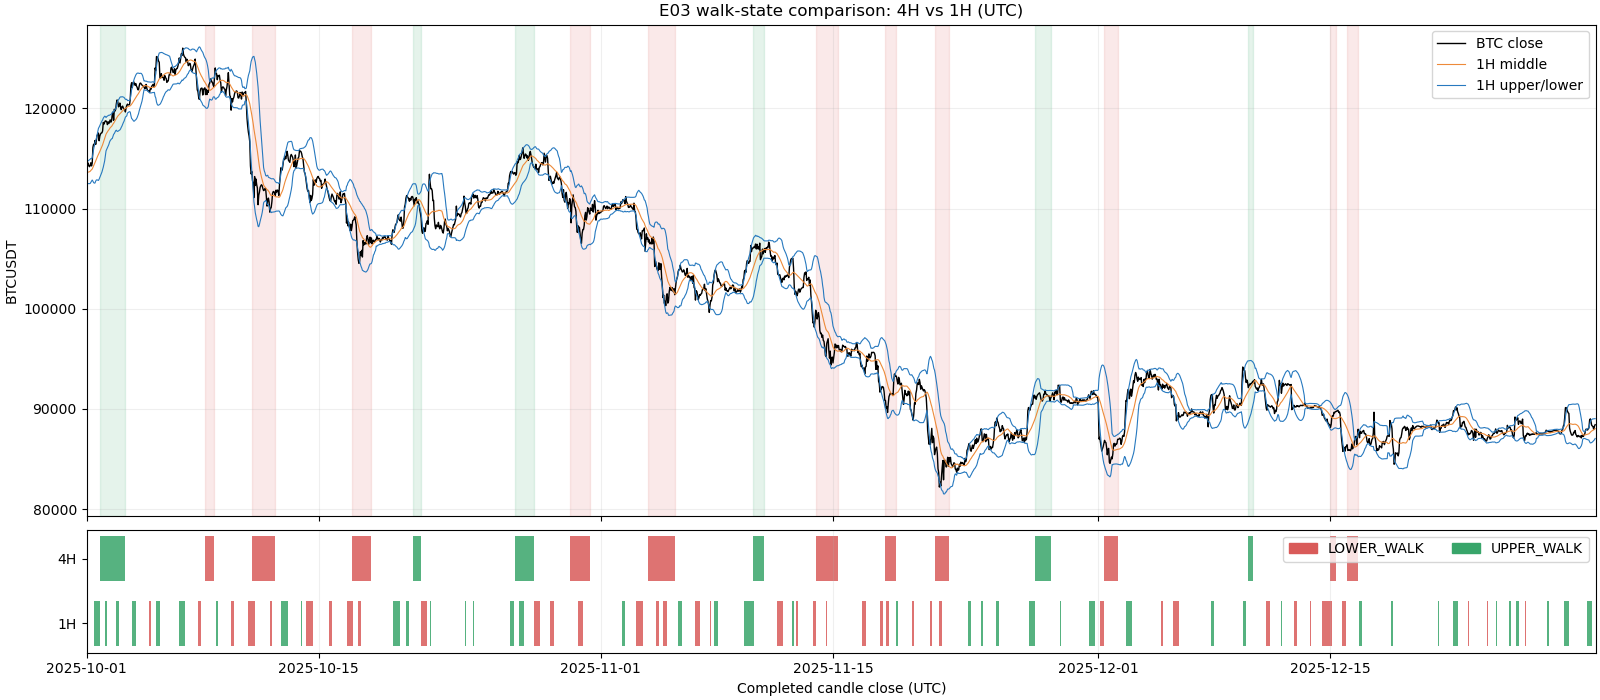

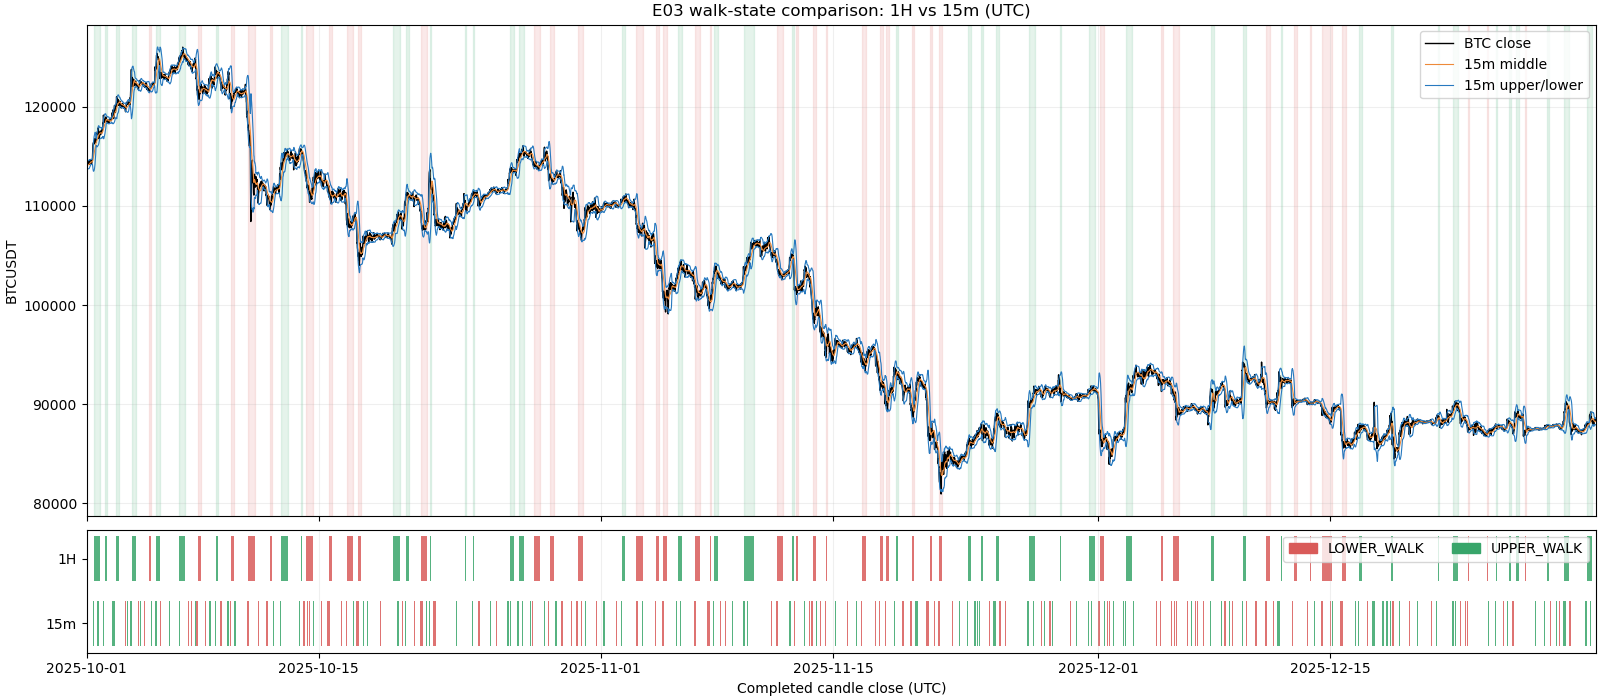

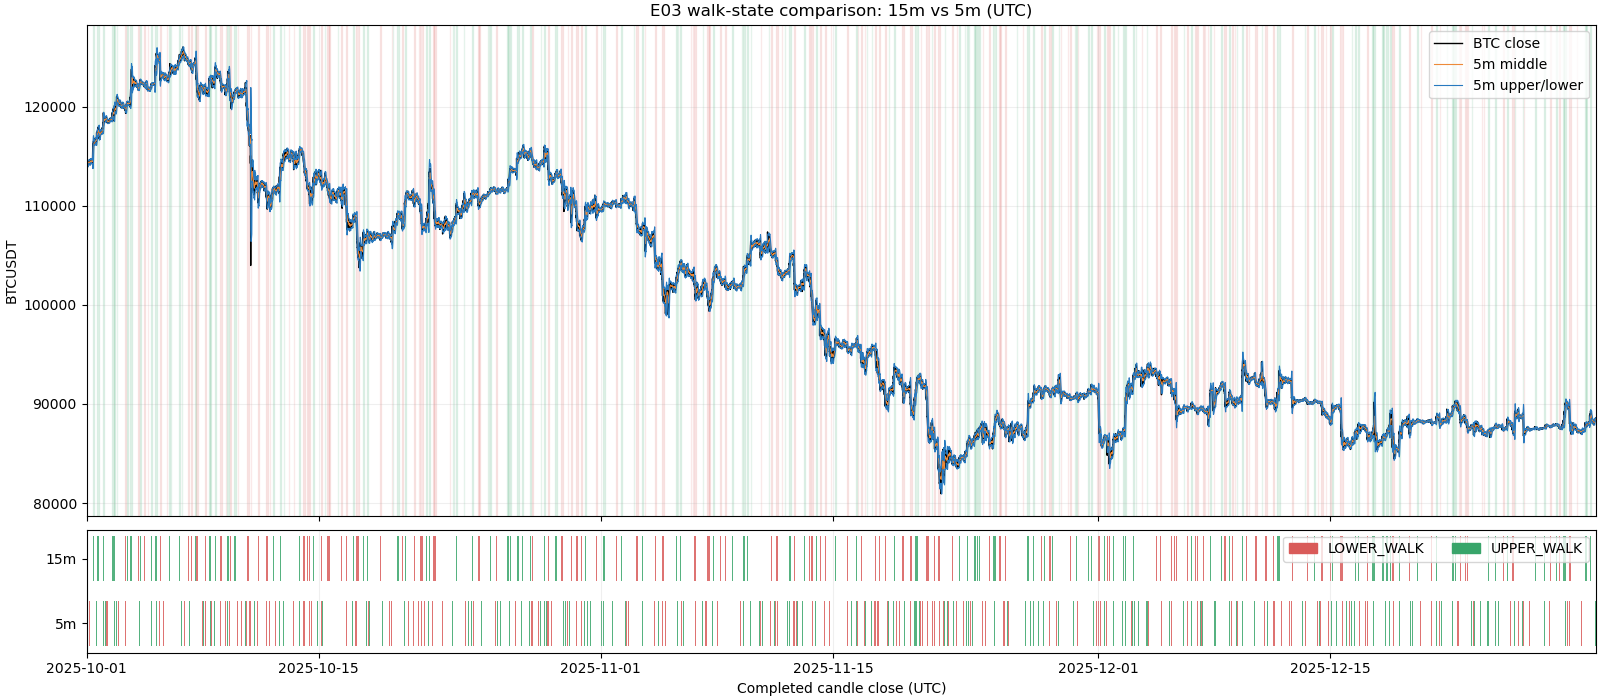

In [10]:
%matplotlib widget
VIEW_START, VIEW_END = "2025-10-01", "2025-12-31"
for coarse,fine in [("4H","1H"),("1H","15m"),("15m","5m")]:
    fig,axes = plot_pair(runs, aligned, coarse, fine, VIEW_START, VIEW_END)
    plt.show()

## 5. Other windows and limitations
Change `VIEW_START`/`VIEW_END` for any historical segment. Test predictiveness later with time-block splits, chronological controls and episode-aware confidence intervals. These conditional overlap tables are **contemporaneous descriptions**, not evidence that higher-timeframe states predict future states.